In [1]:
import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

In [2]:
import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

# print("Updated PATH to include MPI")
# print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/Users/katharinaduecker/miniconda3/envs/hnn-core-env/bin:/Users/katharinaduecker/miniconda3/condabin:/usr/bin:/bin:/usr/sbin:/sbin:/usr/local/bin
Which mpiexec:
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/bin/mpiexec



In [3]:
import os
import os.path as op
from functools import partial

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, average_dipoles, JoblibBackend
from hnn_core.dipole import _rmse, _rmse_corr
import numpy as np

import pickle
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from scipy.stats import pearsonr

pth = '/users/kduecker/hnn-tuning/'

import sys
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color
#from opt_ERP_cma import get_constraints_init_params, set_up_drives_empty
col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255

pathfig = os.path.join(os.getcwd(), 'figures')
os.makedirs(pathfig, exist_ok=True)
n_procs = 20

cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = '42'

filename = op.join(f'{pth}new_model_HNN/ERP','duecker_ET_supra_ERP.json')

ImportError: cannot import name '_rmse_corr' from 'hnn_core.dipole' (/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py)

In [ ]:
pathgen = '/users/kduecker/hnn-tuning/hnn-data/'

data_url = f'{pathgen}MEG_detection_data/S1_SupraT.txt'
exp_dpl = read_dipole(data_url)

In [5]:
with open(f'{pth}/new_model_HNN/ERP/cma_checkpoint.pkl', 'rb') as file:
        checkp =  pickle.load(file)

from hnn_core.optimization.general_optimization import set_params_opt_drives
from opt_ERP_cma import get_constraints_init_params, set_up_drives_empty


_, initial_params = get_constraints_init_params()
predicted_params = checkp['es'].result.xbest
predicted_params = np.array(predicted_params)
params_batch = {name: predicted_params[idx] for idx, name in enumerate(initial_params.keys())}

predicted_params = checkp['es'].result.xbest
with open('erp_supra_pred_params_cma.pkl', 'wb') as file:
    pickle.dump(params_batch, file)

In [6]:
# with open(f'{pth}/new_model_HNN/ERP/cma_checkpoint.pkl', 'rb') as file:
#         checkp =  pickle.load(file)

# max_iter = len(checkp['obj_values'])
# obj = [np.min(checkp['obj_values'][:idx]) for idx in range(1, max_iter + 1)]



# from hnn_core.optimization.general_optimization import set_params_opt_drives
# from opt_ERP_cma import get_constraints_init_params, set_up_drives_empty


# _, initial_params = get_constraints_init_params()
# predicted_params = checkp['es'].result.xbest
# predicted_params = np.array(predicted_params)
# params_batch = {name: predicted_params[idx] for idx, name in enumerate(initial_params.keys())}

# net = duecker_ET_model()
# set_up_drives_empty(net)
# set_params_opt_drives(net, params_batch)

# with JoblibBackend(n_jobs=3):
#         dpl = simulate_dipole(net, tstop=exp_dpl.times[-1], n_trials=3, bsl_cor="duecker")

# #dpl_opt = [d.scale(scaling_factor).smooth(smooth_win) for d in dpl_opt]
# avg_dpl = average_dipoles(dpl)
# plt.plot(avg_dpl.data["agg"])


# with open(f'/users/kduecker/hnn-tuning/new_model_HNN/ERP/prox1/cma_checkpoint.pkl', 'rb') as file:
#         checkp =  pickle.load(file)

# max_iter = len(checkp['obj_values'])
# obj = [np.min(checkp['obj_values'][:idx]) for idx in range(1, max_iter + 1)]



# from hnn_core.optimization.general_optimization import set_params_opt_drives
# from opt_ERP_cma import get_constraints_init_params, set_up_drives_empty


# _, initial_params = get_constraints_init_params()
# predicted_params = checkp['es'].result.xbest
# predicted_params = np.array(predicted_params)
# params_batch = {name: predicted_params[idx] for idx, name in enumerate(initial_params.keys())}

# net = duecker_ET_model()
# set_up_drives_empty(net)
# set_params_opt_drives(net, params_batch)

# with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
#         dpl = simulate_dipole(net, tstop=exp_dpl.times[-1], n_trials=3, bsl_cor="duecker")

# #dpl_opt = [d.scale(scaling_factor).smooth(smooth_win) for d in dpl_opt]
# avg_dpl = average_dipoles(dpl)
# plt.plot(avg_dpl.data["agg"])

In [7]:
with open(f'opt_ERP_cma_150_new_obj.pkl', 'rb') as file:
        optim = pickle.load(file)

In [8]:
data_url = f'{pth}/hnn-data/MEG_detection_data/S1_SupraT.txt'
exp_dpl = read_dipole(data_url)

tstop = exp_dpl.times[-1]
scaling_factor = 1000
smooth_win = 5

In [9]:
from hnn_core import write_network_configuration, read_network_configuration
write_network_configuration(optim.net_, filename)

In [10]:
# dpl_opt = simulate_dipole(optim.net_, tstop=tstop, n_trials=3, dt=0.025, bsl_cor="duecker", record_ca='all', record_vsec='all', record_isec='all')

In [11]:
with JoblibBackend(n_jobs=3):
    dpl_opt = simulate_dipole(optim.net_, tstop=tstop, n_trials=3, dt=0.025, bsl_cor="duecker", record_ca='all', record_vsec='all', record_isec='all')

--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.


In [12]:
dpl_opt = [d.scale(scaling_factor).smooth(smooth_win) for d in dpl_opt]
avg_dpl = average_dipoles(dpl_opt)


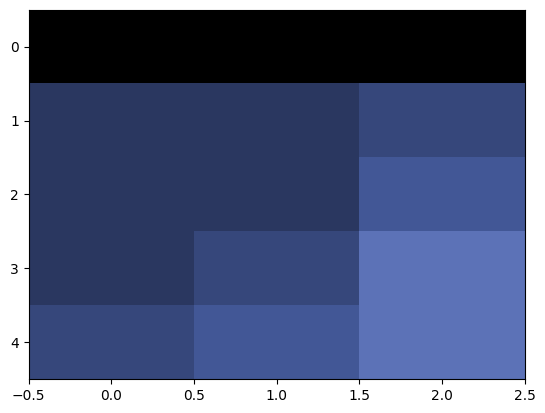

In [13]:
l5_cols_tone = ['k','#2A3760','#36477B','#425796', '#5C72B7']
l5_cols_tone_rgb = np.array([[0,0,0], [42, 55, 96],[54, 71, 123],[66, 87, 150],[92, 114, 183]])/255
l5cmap = matplotlib.colors.ListedColormap(l5_cols_tone_rgb)
iml5 = plt.imshow(l5cmap.colors, aspect='auto', cmap=l5cmap)



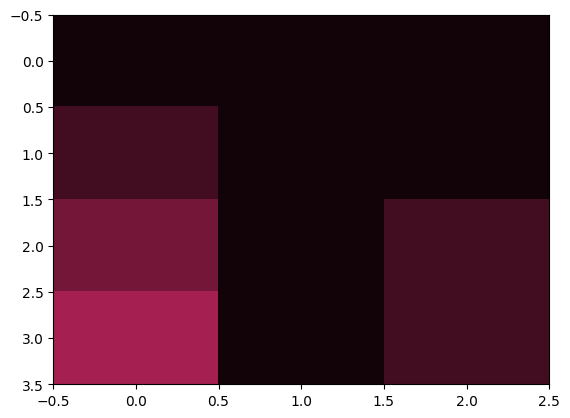

In [14]:

l23_cols_tone = ['#110308', '#420d20', '#741638', '#a52050']
l23_cols_tone_rgb = np.array([[17, 3, 8], [66, 13, 32], [116, 22, 56], [165, 32, 80]])/255
l23cmap = matplotlib.colors.ListedColormap(l23_cols_tone_rgb)
iml2 = plt.imshow(l23cmap.colors, aspect='auto', cmap=l23cmap)

In [15]:
# Block VGGCs to find calcium through NMDA

def net_block_ca(net_no_ca):
    # block Ca
    # 
    net_no_ca.cell_types['L5ET']['cell_object'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
    net_no_ca.cell_types['L5ET']['cell_object'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

    net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
    net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L5ET']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5ET']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
        net_no_ca.cell_types['L5ET']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L5ET']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])

    sections = ['apical_trunk', 'apical_1', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
        net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])


    return net_no_ca

In [16]:
# block Calcium to get NMDA only
net = read_network_configuration(filename)

net_no_ca = net_block_ca(net)
dpl_test = simulate_dipole(net_no_ca, tstop=tstop, n_trials=1, dt=0.025, bsl_cor="duecker", record_ca='all', record_vsec='all')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying dueckerET baseline correction


/tmp/ipykernel_874062/2923791987.py:197: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 2000x800 with 18 Axes> which fig.colorbar is called on.
  cb1 = plt.colorbar(iml5, cax=cax2,orientation='horizontal')


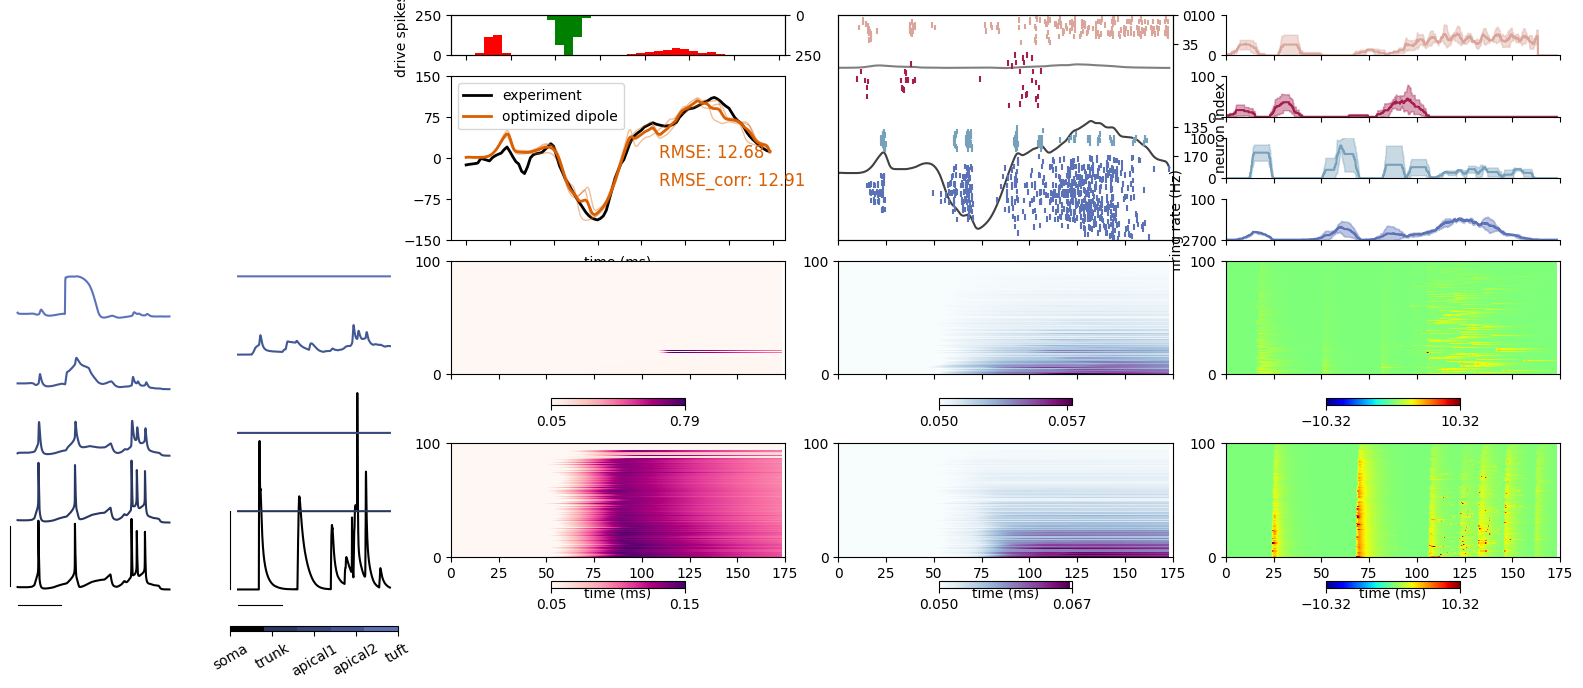

In [19]:
fig = plt.figure(figsize=(20,8))

gs = GridSpec(7, 5, figure=fig, height_ratios=[0.25, 0.25, 0.25, 0.25, 1, 1, 0.03], width_ratios=[0.5, 0.5, 1, 1, 1], hspace=0.3)
ax = [None]*15
ax[0] = fig.add_subplot(gs[0, 2])
ax[1] = fig.add_subplot(gs[1:4, 2])
ax[2] = fig.add_subplot(gs[:4, 3])
ax[3] = fig.add_subplot(gs[0, 4])
ax[4] = fig.add_subplot(gs[1, 4])
ax[5] = fig.add_subplot(gs[2, 4])
ax[6] = fig.add_subplot(gs[3, 4])

ax[7] = fig.add_subplot(gs[4:6, 0])
ax[8] = fig.add_subplot(gs[4:6, 1])
ax[9] = fig.add_subplot(gs[4, 2])
ax[10] = fig.add_subplot(gs[5, 2])
ax[11] = fig.add_subplot(gs[4, 3])
ax[12] = fig.add_subplot(gs[5, 3])

ax[13] = fig.add_subplot(gs[4, 4])
ax[14] = fig.add_subplot(gs[5, 4])

#cax1 = fig.add_subplot(gs[6, 0])
cax2 = fig.add_subplot(gs[6, 1])

# proximal and distal histogram
bins = np.arange(0, tstop, 5)  # histogram bins

spike_prox1 = np.array(optim.net_.cell_response.spike_times_by_type['prox1'][0]).reshape(-1,1)
spike_dist = np.array(optim.net_.cell_response.spike_times_by_type['dist1'][0]).reshape(-1,1)
spike_prox2 = np.array(optim.net_.cell_response.spike_times_by_type['prox2'][0]).reshape(-1,1)

ax[0].hist(spike_prox1, bins, color='r')
ax[0].set_ylim([0, 250])
ax[0].set_ylabel('drive spikes')
ax[0].hist(spike_prox2, bins, color='r')
ax[0].set_xticklabels([])

ax1tw = ax[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 250])
ax1tw.invert_yaxis()
ax1tw.set_xticklabels([])

# ERP dipole
ax[1].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
for dpl in dpl_opt:
    ax[1].plot(dpl.times,dpl.data['agg'], color=col_lines[1], linewidth=1, alpha=0.4)

ax[1].plot(avg_dpl.times,avg_dpl.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)
#ax[1, 0].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1].set_ylim([-150, 150])
ax[1].set_yticks([-150, -75, 0, 75, 150])
ax[1].text(110, 0.5, 'RMSE: %.2f' % _rmse(avg_dpl, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[1])
ax[1].text(110, -50, 'RMSE_corr: %.2f' % _rmse_corr(avg_dpl, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[1])

ax[1].legend()
ax[1].set_xlabel('time (ms)')

# Spiking

ax[2].plot(avg_dpl.times, avg_dpl.data['L2']+100, color='k', alpha=0.5)
ax[2].plot(avg_dpl.times, avg_dpl.data['L5']-100, color='k', alpha=0.75)
ax[2].set_ylim([-225, 200])
ax[2].set_yticks([])
axtw = ax[2].twinx()
for t in range(len(optim.net_.cell_response.spike_gids)):
    I = np.array(optim.net_.cell_response.spike_gids[t]) <270
    gids = np.array(optim.net_.cell_response.spike_gids[t]).reshape(-1,)[I]
    times = np.array(optim.net_.cell_response.spike_times[t]).reshape(-1,)[I]


    colors = [assign_color(optim.net_, gid) for gid in gids]

    axtw.scatter(times, gids, s=16, alpha=1., c=colors, marker='|')
axtw.set_ylabel('neuron index')
axtw.set_xlim([0, 175])
axtw.set_ylim([0, 270])
axtw.set_yticks([0, 35, 135, 170, 270])
axtw.invert_yaxis()
axtw.set_xticks(np.arange(0, 176, 25))
axtw.set_xlim((0, 175))

ax[1].set_xticklabels([])
ax[2].set_xticklabels([])
axtw.set_xticklabels([])

#cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5ET']
## Firing rates
t_winl_ms = 10
t_winl_samp = int(t_winl_ms*(avg_dpl.sfreq/1000))
fr_cell_types = np.zeros((len(dpl_opt), 4, len(avg_dpl.times)))
cell_types = list(optim.net_.cell_types.keys())
ylims = [[0, 100], [0, 100], [0, 100], [0, 100]]
for t in range(len(dpl_opt)):
    spike_gids = np.array(optim.net_.cell_response.spike_gids[t])
    spike_times = np.array(optim.net_.cell_response.spike_times[t])[spike_gids < 270]
    spike_gids = spike_gids[spike_gids < 270]
    fr_cell = np.zeros((270, len(avg_dpl.times)))
    t_start_samp = 0
    
    i = 0
    while t_start_samp < len(optim.net_.cell_response.times)-t_winl_samp+1:
        t_start_ms = t_start_samp*(1000/avg_dpl.sfreq)
        
        cur_spike_times = ((spike_times > t_start_ms) & (spike_times < t_start_ms+t_winl_ms))
        if cur_spike_times.any():
            cur_spike_gid, count = np.unique(spike_gids[cur_spike_times], return_counts=True)
            for gid, c in zip(cur_spike_gid, count):
                fr_cell[int(gid), t_start_samp] = (c/t_winl_ms*1000)
        t_start_samp +=1

    for c, cell_type in enumerate(cell_types):
        gid_range = optim.net_.gid_ranges[cell_type]
        cell_type_fr = fr_cell[gid_range, :]
        cell_type_fr = cell_type_fr[np.sum(cell_type_fr, axis=1)>0]
        fr_cell_types[t, c, :] = np.mean(cell_type_fr, axis=0)

for c, cell_type in enumerate(cell_types):
    i = 2+c+1
    ax[i].plot(avg_dpl.times, np.mean(fr_cell_types[:,c, :], axis=0), color=cm_neurons[c])
    ax[i].fill_between(avg_dpl.times,
                      np.mean(fr_cell_types[:,c, :], axis=0) - np.std(fr_cell_types[:,c, :], axis=0),
                      np.mean(fr_cell_types[:,c, :], axis=0) + np.std(fr_cell_types[:,c, :], axis=0),
                      color=cm_neurons[c], alpha=0.4)
    ax[i].set_xlim((0, 175))
    ax[i].set_xticks(np.arange(0, 176, 25))
    ax[i].set_xticklabels([])

    if c<3:
        ax[i].set_xticklabels([])
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)
    ax[i].set_ylim(ylims[c])
    ax[i].set_yticks(ylims[c])
ax[i].set_ylabel('firing rate (Hz)')

# L23 membrane potential

# l23_gids = np.array(optim.net_.cell_response.spike_gids[0])[(np.array(optim.net_.cell_response.spike_gids[0]) < 135) & (np.array(optim.net_.cell_response.spike_gids[0]) > 35)]
# l23_spikes, counts = np.unique(l23_gids, return_counts=True)
# gid_oi = int(l23_spikes[np.argmax(counts)])# example that shows distal drive Ca spike

# sections = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
# L = []
# for section in sections:
#     L.append(optim.net_.cell_types["L2_pyramidal"]['cell_object'].sections[section].L)
# prevL = 0
# for i, section in enumerate(sections):

#     v = np.array(optim.net_.cell_response.vsec[0][gid_oi][section])
#     ax[7].plot(optim.net_.cell_response.times, v + i*110, color=l23_cols_tone[i], linewidth=1.5)
# ax[7].spines['left'].set_bounds([-70, 30])
# ax[7].spines['bottom'].set_bounds([0, 50])
# ax[7].set_xticks([])
# ax[7].set_yticks([])
# ax[7].spines['top'].set_visible(False)
# ax[7].spines['right'].set_visible(False)

# cb1 = plt.colorbar(iml2, cax=cax1,orientation='horizontal')
# cb1.ax.set_xticks(np.linspace(0.,np.max(l23cmap.colors),4))
# cb1.ax.set_xticklabels(['soma','trunk','apical1','tuft'], rotation=30)

# L5 membrane potential

l5_gids = np.array(optim.net_.cell_response.spike_gids[0])[(np.array(optim.net_.cell_response.spike_gids[0]) >= 170) & (np.array(optim.net_.cell_response.spike_gids[0]) < 270)]
l5_spikes, counts = np.unique(l5_gids, return_counts=True)
gid_oi = int(l5_spikes[np.argmax(counts)])      

sections = ['soma','apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(optim.net_.cell_types["L5ET"]['cell_object'].sections[section].L)
prevL = 0

for i, section in enumerate(sections):

    v = np.array(optim.net_.cell_response.vsec[0][gid_oi][section])
    isec = np.array(optim.net_.cell_response.isec[0][gid_oi][section][f'{section}_gabaa'])
    ax[7].plot(optim.net_.cell_response.times, v + i*110, color=l5_cols_tone[i], linewidth=1.5)
    ax[8].plot(optim.net_.cell_response.times, isec + i*4, color=l5_cols_tone[i], linewidth=1.5)

ax[7].spines['left'].set_bounds([-70, 30])
ax[7].spines['bottom'].set_bounds([0, 50])
ax[7].set_xticks([])
ax[7].set_yticks([])
ax[7].spines['top'].set_visible(False)
ax[7].spines['right'].set_visible(False)

ax[8].spines['left'].set_bounds([0, 4])
ax[8].spines['bottom'].set_bounds([0, 50])
ax[8].set_xticks([])
ax[8].set_yticks([])
ax[8].spines['top'].set_visible(False)
ax[8].spines['right'].set_visible(False)

cb1 = plt.colorbar(iml5, cax=cax2,orientation='horizontal')
cb1.ax.set_xticks(np.linspace(0.,np.max(l5cmap.colors),5))
cb1.ax.set_xticklabels(['soma','trunk','apical1','apical2','tuft'], rotation=30)
# ax[9].spines['left'].set_bounds([0, 2])
# ax[9].spines['bottom'].set_bounds([0, 50])
# ax[9].set_xticks([])
# ax[9].set_yticks([])
# ax[9].spines['top'].set_visible(False)
# ax[9].spines['right'].set_visible(False)



## CALCIUM
# L23 calcium 
l23_tuft_ca = np.zeros((100, len(avg_dpl.times)))

# sort gids based on distance

l23idx = np.argsort(np.sum(np.abs(np.array(optim.net_.pos_dict["L2_pyramidal"]) - np.array([4,4,1.3074e+03])), axis=1))
for idx,i in enumerate(l23idx):
    gid = optim.net_.gid_ranges["L2_pyramidal"][i]
    l23_tuft_ca[idx] = optim.net_.cell_response.ca[0][gid]['apical_tuft']
    idx+=1
    
# convert to micro molar
l23_tuft_ca *=1e3
im = ax[9].pcolormesh(optim.net_.cell_response.times, np.arange(100), l23_tuft_ca, shading='auto', cmap='RdPu', rasterized=True)
cb1 = plt.colorbar(im, ax=ax[9], orientation='horizontal', shrink=0.4)
cb1.set_ticks([5e-2, l23_tuft_ca.max()])
cb1.set_ticklabels([f'{5e-2:.1}', f'{l23_tuft_ca.max():.2}'])
ax[9].set_ylim([0, 100])
ax[9].set_yticks([0, 100])
ax[9].set_xlim([0, 175])
ax[9].set_xticklabels([])
# L5 calcium
l5_tuft_ca = np.zeros((100, len(avg_dpl.times)))

l5idx = np.argsort(np.sum(np.abs(np.array(optim.net_.pos_dict["L5ET"]) - np.array([4,4,1.3074e+03])), axis=1))
for idx,i in enumerate(l5idx):
    gid = optim.net_.gid_ranges["L5ET"][i]
    l5_tuft_ca[idx] = optim.net_.cell_response.ca[0][gid]['apical_tuft']
    idx+=1

# convert to micromolar
l5_tuft_ca *=1e3
im = ax[10].pcolormesh(optim.net_.cell_response.times, np.arange(100), l5_tuft_ca, shading='auto', cmap='RdPu', rasterized=True, vmax=l5_tuft_ca.max())
cb3 = plt.colorbar(im, ax=ax[10], orientation='horizontal', shrink=0.4)
cb3.set_ticks([5e-2, l5_tuft_ca.max()])
cb3.set_ticklabels([f'{5e-2:.1}', f'{l5_tuft_ca.max():.2}'])
ax[10].set_ylim([0, 100])
ax[10].set_yticks([0, 100])
ax[10].set_xlim([0, 175])
ax[10].set_xlabel('time (ms)')


# NMDA calcium only (VGGC blocked)

# L23 calcium 
l23_tuft_ca = np.zeros((100, len(avg_dpl.times)))

# sort gids based on distance

l23idx = np.argsort(np.sum(np.abs(np.array(net_no_ca.pos_dict["L2_pyramidal"]) - np.array([4,4,1.3074e+03])), axis=1))
for idx, i in enumerate(l23idx):
    gid = net_no_ca.gid_ranges["L2_pyramidal"][i]
    l23_tuft_ca[idx] = net_no_ca.cell_response.ca[0][gid]['apical_tuft']
    idx+=1
    
# convert to micro molar
#l23_tuft_ca -= 5e-5
l23_tuft_ca *=1e3
im = ax[11].pcolormesh(net_no_ca.cell_response.times, np.arange(100), l23_tuft_ca, shading='auto', cmap='BuPu', rasterized=True)
cb1 = plt.colorbar(im, ax=ax[11], orientation='horizontal', shrink=0.4)
cb1.set_ticks([l23_tuft_ca.min(), np.round(l23_tuft_ca.max(),3)])
#cb1.set_ticklabels([f'{5e-2:.5}', f'{l23_tuft_ca.max():.5}'])
ax[11].set_ylim([0, 100])
ax[11].set_yticks([0, 100])
ax[11].set_xlim([0, 175])
ax[11].set_xticklabels([])
# L5 calcium
l5_tuft_ca = np.zeros((100, len(avg_dpl.times)))

l5idx = np.argsort(np.sum(np.abs(np.array(net_no_ca.pos_dict["L5ET"]) - np.array([4,4,1.3074e+03])), axis=1))

for idx, i in enumerate(l5idx):
    gid = net_no_ca.gid_ranges["L5ET"][i]
    l5_tuft_ca[idx] = net_no_ca.cell_response.ca[0][gid]['apical_tuft']
    idx+=1

# convert to micromolar
#l5_tuft_ca -= 5e-5
l5_tuft_ca *=1e3
im = ax[12].pcolormesh(net_no_ca.cell_response.times, np.arange(100), l5_tuft_ca, shading='auto', cmap='BuPu', rasterized=True, vmax=l5_tuft_ca.max())
cb3 = plt.colorbar(im, ax=ax[12], orientation='horizontal', shrink=0.4)
cb3.set_ticks([l5_tuft_ca.min(), np.round(l5_tuft_ca.max(),3)])
#cb3.set_ticklabels([f'{5e-2:.5}', f'{l5_tuft_ca.max():.5}'])
ax[12].set_ylim([0, 100])
ax[12].set_yticks([0, 100])
ax[12].set_xlim([0, 175])
ax[12].set_xlabel('time (ms)')


## GABAA inhibition at soma
l23_soma_gabaa = np.zeros((100, len(avg_dpl.times)))
for idx, i in enumerate(l23idx):
    gid = optim.net_.gid_ranges["L2_pyramidal"][i]
    l23_soma_gabaa[idx] = optim.net_.cell_response.isec[0][gid]['soma']['soma_gabaa']
    idx+=1
#fig.tight_layout()
im = ax[13].pcolormesh(optim.net_.cell_response.times, np.arange(100), l23_soma_gabaa, shading='auto', cmap='jet', rasterized=True, vmin = -l23_soma_gabaa.max(), vmax=l23_soma_gabaa.max())
cb4 = plt.colorbar(im, ax=ax[13], orientation='horizontal', shrink=0.4)
cb4.set_ticks([-np.round(l23_soma_gabaa.max(),2), np.round(l23_soma_gabaa.max(),2)])

ax[13].set_ylim([0, 100])
ax[13].set_yticks([0, 100])
ax[13].set_xlim([0, 175])
ax[13].set_xticklabels([])
l5_soma_gabaa = np.zeros((100, len(avg_dpl.times)))
for idx, i in enumerate(l5idx):
    gid = optim.net_.gid_ranges["L5ET"][i]
    l5_soma_gabaa[idx] = optim.net_.cell_response.isec[0][gid]['soma']['soma_gabaa']
    idx+=1
#fig.tight_layout()
im = ax[14].pcolormesh(optim.net_.cell_response.times, np.arange(100), l5_soma_gabaa, shading='auto', cmap='jet', rasterized=True, vmin = -l23_soma_gabaa.max(), vmax=l23_soma_gabaa.max())
cb5 = plt.colorbar(im, ax=ax[14], orientation='horizontal', shrink=0.4)
cb5.set_ticks([-np.round(l23_soma_gabaa.max(),2), np.round(l23_soma_gabaa.max(),2)])

#cb4.set_ticks([l5_tuft_ca.min(), np.round(l5_tuft_ca.max(),3)])
ax[14].set_ylim([0, 100])
ax[14].set_yticks([0, 100])
ax[14].set_xlim([0, 175])
ax[14].set_xlabel('time (ms)')
fig.savefig(os.path.join(pathfig, 'duecker_ET_optim_ERP.png'), dpi=300)
fig.savefig(os.path.join(pathfig, 'duecker_ET_optim_ERP.pdf'), dpi=300)


In [27]:
optim.net_.external_drives['prox1']['weights_nmda']

{'L2_basket': np.float64(0.009512212747374448),
 'L2_pyramidal': np.float64(0.025286771063775682),
 'L5_basket': np.float64(2.6102597290994365e-12),
 'L5ET': np.float64(0.05644074642301043)}

In [18]:
fig, ax = plt.subplots(10,10, figsize=(20, 10))
ax = ax.flatten()
for i, gid in enumerate(optim.net_.gid_ranges['L5ET']):
    v = np.array(optim.net_.cell_response.vsec[0][gid]["soma"])
    ax[i].plot(optim.net_.cell_response.times, v)

Error in callback <function flush_figures at 0x7faaea5bb560> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [19]:
optim.net_.external_drives['prox1']['weights_nmda']

{'L2_basket': np.float64(0.009512212747374448),
 'L2_pyramidal': np.float64(0.025286771063775682),
 'L5_basket': np.float64(2.6102597290994365e-12),
 'L5ET': np.float64(0.05644074642301043)}